**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Clase 20 - SQL y manejo de tablas**

## Complemento

Este notebook va en paralelo con la presentación **`SQL_y_manejo_de_tablas.html`** (carpeta `PPT's/` del repo;
descargala y abrila con el navegador). En la presentación está la idea; acá, cómo se escribe.

## ¿Qué vamos a hacer en esta clase?

Todo lo que vimos hasta ahora arrancaba con un archivo. Pero en una organización de verdad los datos
**no viven en archivos sueltos**: viven en una **base de datos**. Y a las bases de datos se les habla
en un idioma que tiene 50 años y no piensa jubilarse: **SQL**.

| Parte | Tema | Cláusula |
|---|---|---|
| **A** | Por qué SQL y no un Excel | — |
| **B** | Armar la base y mirarla | `sqlite3` |
| **C** | Traer datos y filtrar | `SELECT` · `WHERE` · `ORDER BY` · `DISTINCT` · `NULL` |
| **D** | Resumir | `COUNT` · `SUM` · `AVG` · `GROUP BY` · `HAVING` |
| **E** | **Cruzar tablas: el corazón de la clase** | `JOIN` · `LEFT JOIN` |
| **F** | Preguntas dentro de preguntas (solo para conocerlas) | Subconsultas |
| **G** | El diccionario SQL ↔ pandas | — |

Al final hay un apéndice **Para ir más lejos** (funciones de fila, fechas y más ejercicios). Es opcional.

> **Por qué te sirve:** "¿sabés SQL?" es literalmente la primera pregunta en una entrevista de análisis
> de datos, control de gestión o auditoría. Es la habilidad técnica más pedida y la más fácil de aprender
> de todas las que vimos.

> ✅ **No hay que instalar nada.** Usamos `sqlite3`, que ya viene adentro de Python.

In [1]:
import sqlite3                     # sqlite3: motor de base de datos incluido en Python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
URL = "https://raw.githubusercontent.com/Datso653/Laboratorio-de-metodos-Cuantitativos-Aplicados-a-la-gestion/main/DF/"

---
# 🤔 Parte A — ¿Por qué SQL si ya sé pandas?

Las dos herramientas hacen lo mismo. La diferencia está en **dónde viven los datos**.

| | pandas | SQL |
|---|---|---|
| Dónde están los datos | En la memoria de tu computadora | En un servidor, ordenados |
| Cuánto aguanta | Lo que entre en tu RAM | Millones de filas sin despeinarse |
| Quién más lo usa | Analistas | Analistas, sistemas, la empresa entera |
| Varias personas a la vez | No | Sí |

**En criollo:** pandas es tu escritorio, SQL es el archivo central de la empresa. Vas al archivo central,
pedís *solo lo que necesitás*, y eso lo traés a tu escritorio para trabajarlo.

### Un poco de vocabulario

| Término | En Excel sería | En pandas sería |
|---|---|---|
| **Base de datos** | El archivo entero | — |
| **Tabla** | Una hoja | Un DataFrame |
| **Registro** (fila) | Una fila | Una fila |
| **Campo** (columna) | Una columna | Una columna |
| **Clave primaria** | La columna de ID única | El índice |
| **Consulta** (*query*) | Un filtro o tabla dinámica | Una línea de código |

---
# 🗄️ Parte B — Armamos nuestra base de datos

Vamos a construir la base de una distribuidora de tecnología con **tres tablas**:

| Tabla | Qué guarda | Filas |
|---|---|---|
| `ventas` | Cada operación de venta | 201 |
| `productos` | El catálogo: categoría y costo | 6 |
| `vendedores` | El equipo comercial y su sucursal | 6 |

Esta forma de organizar —una tabla de **hechos** rodeada de tablas de **referencia**— es la más común
en cualquier empresa. Se llama *modelo estrella*.

In [2]:
# 1) Traemos las ventas del repositorio
ventas = pd.read_csv(URL + "ventas.csv")
ventas["Total"] = ventas["Cantidad"] * ventas["Precio_Unitario"]

# 2) Creamos el catálogo de productos
productos = pd.DataFrame({
    "Producto":  ["Notebook", "Monitor", "Impresora", "Teclado", "Mouse", "Auriculares"],
    "Categoria": ["Cómputo", "Cómputo", "Periférico", "Periférico", "Periférico", "Audio"],
    "Costo":     [640000, 165000, 180000, 21000, 9500, 24000],
})

# 3) Y el equipo de ventas
vendedores = pd.DataFrame({
    "Vendedor":  ["Juan", "Lucía", "María", "Pedro", "Sofía"],
    "Sucursal":  ["Centro", "Norte", "Centro", "Sur", "Norte"],
    "Antiguedad": [8, 3, 12, 1, 5],
})

print("ventas:", ventas.shape, "| productos:", productos.shape, "| vendedores:", vendedores.shape)
ventas.head(3)

ventas: (200, 7) | productos: (6, 3) | vendedores: (5, 3)


,Fecha,Producto,Vendedor,Ciudad,Cantidad,Precio_Unitario,Total
0,2024-01-01,Monitor,Juan,Mendoza,6,215200,1291200
1,2024-01-02,Notebook,Lucía,La Plata,7,873800,6116600
2,2024-01-03,Teclado,Juan,Córdoba,3,34800,104400


### 🧹 Dos datos "de la vida real"

Las bases de verdad nunca están perfectas. Le agregamos **a propósito** dos cosas que en cualquier
empresa pasan todo el tiempo, y que vamos a ir encontrando a lo largo de la clase:

1. **Una venta cargada a las apuradas:** un producto nuevo (`Parlante`) que todavía no se dio de alta
   en el catálogo, y **sin ciudad** (fue una venta online).
2. **Un vendedor recién ingresado** (`Tomás`) que todavía no hizo ninguna venta.

In [3]:
# 1) Una venta de un producto que NO está en el catálogo, y sin ciudad cargada
venta_rara = pd.DataFrame({
    "Fecha":           ["2024-07-15"],
    "Producto":        ["Parlante"],
    "Vendedor":        ["Sofía"],
    "Ciudad":          [None],          # None = dato faltante
    "Cantidad":        [4],
    "Precio_Unitario": [62000],
})
venta_rara["Total"] = venta_rara["Cantidad"] * venta_rara["Precio_Unitario"]
ventas = pd.concat([ventas, venta_rara], ignore_index=True)

# 2) Un vendedor nuevo, que todavía no vendió nada
nuevo = pd.DataFrame({"Vendedor": ["Tomás"], "Sucursal": ["Sur"], "Antiguedad": [0]})
vendedores = pd.concat([vendedores, nuevo], ignore_index=True)

print("ventas:", ventas.shape, "| vendedores:", vendedores.shape)

ventas: (201, 7) | vendedores: (6, 3)


In [4]:
# Creamos la base de datos en memoria y volcamos las tres tablas
con = sqlite3.connect(":memory:")     # ":memory:" = base temporal en RAM (se borra al cerrar)

ventas.to_sql("ventas", con, index=False, if_exists="replace")
productos.to_sql("productos", con, index=False, if_exists="replace")
vendedores.to_sql("vendedores", con, index=False, if_exists="replace")

print("Base creada ✅")

Base creada ✅


> 📌 **`:memory:`** crea una base que vive solo mientras dure la sesión. Si querés un archivo de verdad
> en el disco, se pone el nombre: `sqlite3.connect("empresa.db")`. Todo lo demás es igual.

In [5]:
# Esta función la vamos a usar en toda la clase: manda una consulta y devuelve un DataFrame
def sql(consulta):
    return pd.read_sql_query(consulta, con)

# Probémosla: ¿qué tablas tiene la base?
sql("SELECT name FROM sqlite_master WHERE type='table'")

,name
0,ventas
1,productos
2,vendedores


### 🔑 Las claves de nuestra base

Cada tabla tiene una columna que **identifica** cada fila (la *clave primaria*), y algunas tienen
columnas que **apuntan a otra tabla** (las *claves foráneas*):

| Tabla | Clave primaria | Claves foráneas |
|---|---|---|
| `productos` | `Producto` | — |
| `vendedores` | `Vendedor` | — |
| `ventas` | — (cada fila es una operación) | `Producto` → `productos` · `Vendedor` → `vendedores` |

> 📌 Las claves foráneas son **las columnas por las que después vamos a cruzar las tablas** con `JOIN`.
> Al final de la clase vemos cómo se declaran en la base para que ella misma las controle.

---
# 🔍 Parte C — `SELECT`: traer datos

La estructura básica de toda consulta SQL es siempre la misma:

```sql
SELECT   columnas          -- qué quiero
FROM     tabla             -- de dónde
WHERE    condición         -- qué filas
ORDER BY columna           -- cómo ordenado
LIMIT    n                 -- cuántas
```

Se lee casi como una oración en inglés. Empecemos por lo mínimo.

In [6]:
# El asterisco * significa "todas las columnas"
sql("SELECT * FROM ventas LIMIT 5")

,Fecha,Producto,Vendedor,Ciudad,Cantidad,Precio_Unitario,Total
0,2024-01-01,Monitor,Juan,Mendoza,6,215200,1291200
1,2024-01-02,Notebook,Lucía,La Plata,7,873800,6116600
2,2024-01-03,Teclado,Juan,Córdoba,3,34800,104400
3,2024-01-04,Notebook,Juan,Mendoza,7,828000,5796000
4,2024-01-05,Notebook,María,Córdoba,3,825300,2475900


In [7]:
# Pedimos solo algunas columnas, en el orden que queramos
sql("""
    SELECT Fecha, Producto, Vendedor, Total
    FROM ventas
    LIMIT 5
""")

,Fecha,Producto,Vendedor,Total
0,2024-01-01,Monitor,Juan,1291200
1,2024-01-02,Notebook,Lucía,6116600
2,2024-01-03,Teclado,Juan,104400
3,2024-01-04,Notebook,Juan,5796000
4,2024-01-05,Notebook,María,2475900


> 💡 Las **comillas triples** `""" """` permiten escribir la consulta en varias líneas.
> A partir de acá las usamos siempre: una consulta SQL bien indentada se lee muchísimo mejor.
>
> Por convención, las **palabras de SQL van en mayúscula** (`SELECT`, `FROM`, `WHERE`) y los nombres de
> tablas y columnas se escriben tal cual están en la base. No es obligatorio, pero todo el mundo lo hace.

### `WHERE`: filtrar filas

Es el equivalente exacto de `ventas[ventas["Ciudad"] == "Córdoba"]` en pandas.

In [8]:
sql("""
    SELECT Fecha, Producto, Vendedor, Total
    FROM ventas
    WHERE Ciudad = 'Córdoba'
    LIMIT 5
""")

,Fecha,Producto,Vendedor,Total
0,2024-01-03,Teclado,Juan,104400
1,2024-01-05,Notebook,María,2475900
2,2024-01-10,Notebook,Juan,5709900
3,2024-01-11,Monitor,Sofía,251500
4,2024-01-13,Impresora,Juan,2403900


| Operador | Qué hace | Ejemplo |
|---|---|---|
| `=` | Igual (¡uno solo, no `==`!) | `WHERE Ciudad = 'Rosario'` |
| `<>` o `!=` | Distinto | `WHERE Producto <> 'Mouse'` |
| `>` `<` `>=` `<=` | Comparación | `WHERE Total > 100000` |
| `AND` / `OR` | Combinar condiciones | `WHERE Total > 100000 AND Ciudad = 'Rosario'` |
| `IN` | Está en una lista | `WHERE Producto IN ('Monitor', 'Notebook')` |
| `BETWEEN` | Entre dos valores | `WHERE Cantidad BETWEEN 3 AND 6` |
| `LIKE` | Coincide con un patrón | `WHERE Producto LIKE 'Note%'` |
| `IS NULL` | Falta el dato | `WHERE Ciudad IS NULL` |

> ⚠️ **Dos trampas clásicas para el que viene de Python:**
> 1. En SQL la igualdad es **`=`**, no `==`.
> 2. El texto va entre **comillas simples**: `'Córdoba'`.

In [9]:
# Varias condiciones a la vez
sql("""
    SELECT Fecha, Producto, Ciudad, Cantidad, Total
    FROM ventas
    WHERE Total > 2000000
      AND Producto IN ('Notebook', 'Monitor')
    ORDER BY Total DESC
    LIMIT 8
""")

,Fecha,Producto,Ciudad,Cantidad,Total
0,2024-03-02,Notebook,Mendoza,9,7384500
1,2024-06-11,Notebook,Córdoba,9,7253100
2,2024-06-02,Notebook,Buenos Aires,9,7250400
3,2024-01-02,Notebook,La Plata,7,6116600
4,2024-07-12,Notebook,Buenos Aires,7,6041700
5,2024-01-04,Notebook,Mendoza,7,5796000
6,2024-05-03,Notebook,La Plata,7,5734400
7,2024-01-10,Notebook,Córdoba,7,5709900


`ORDER BY Total DESC` ordena de mayor a menor (`DESC` = *descending*). Sin el `DESC` ordena de menor a mayor.

### `DISTINCT`: sacar los repetidos

¿En qué ciudades vendimos? Si pedís `SELECT Ciudad FROM ventas` te devuelve **una fila por venta**:
201 filas, con cada ciudad repetida decenas de veces. `DISTINCT` se queda con **un ejemplar de cada valor**.

In [10]:
# Sin DISTINCT: una fila por venta
sin_distinct = sql("""
    SELECT Ciudad
    FROM ventas
""")
print("Sin DISTINCT:", len(sin_distinct), "filas")

# Con DISTINCT: cada ciudad una sola vez
sql("""
    SELECT DISTINCT Ciudad
    FROM ventas
    ORDER BY Ciudad
""")

Sin DISTINCT: 201 filas


,Ciudad
0,None
1,Buenos Aires
2,Córdoba
3,La Plata
4,Mendoza
5,Rosario


Fijate que aparece un `None`: es la venta sin ciudad. Volvemos a ella en un rato.

**Ojo: `DISTINCT` mira la fila entera**, no una columna. Si pedís dos columnas, te devuelve las
**combinaciones** distintas:

In [11]:
# ¿Qué productos vendió cada vendedor? Combinaciones únicas de (Vendedor, Producto)
sql("""
    SELECT DISTINCT Vendedor, Producto
    FROM ventas
    ORDER BY Vendedor, Producto
""")

,Vendedor,Producto
0,Juan,Auriculares
1,Juan,Impresora
2,Juan,Monitor
3,Juan,Mouse
4,Juan,Notebook
5,Juan,Teclado
6,Lucía,Auriculares
7,Lucía,Impresora
8,Lucía,Monitor
9,Lucía,Mouse


> 💡 **Para qué se usa en la práctica:** para responder *"¿cuáles hay?"* (qué clientes compraron, qué
> productos se vendieron en Rosario, qué sucursales tienen ventas). Y, sobre todo, para **contar sin
> duplicar**: *"¿cuántos clientes distintos compraron?"* no es lo mismo que *"¿cuántas compras hubo?"*.


### `NULL`: el dato que falta

En SQL, una celda vacía no es un cero ni un texto vacío: es **`NULL`**, que significa *"no sé"*.
Y tiene una regla que sorprende a todos: **`NULL` no es igual a nada, ni siquiera a otro `NULL`**.
Por eso no se busca con `=`:

In [12]:
# ❌ Con = no encuentra nada (comparar contra "no sé" da "no sé")
con_igual = sql("""
    SELECT *
    FROM ventas
    WHERE Ciudad = NULL
""")
print("Con = NULL:", len(con_igual), "filas")

# ✅ Con IS NULL sí
sql("""
    SELECT *
    FROM ventas
    WHERE Ciudad IS NULL
""")

Con = NULL: 0 filas


,Fecha,Producto,Vendedor,Ciudad,Cantidad,Precio_Unitario,Total
0,2024-07-15,Parlante,Sofía,None,4,62000,248000


> ⚠️ **Siempre `IS NULL` / `IS NOT NULL`, nunca `= NULL`.** No da error: simplemente devuelve cero
> filas, y por eso es tan peligroso.
>
> Cuando lo traés a pandas, el `NULL` se ve como `None` o `NaN`. Es lo mismo: el dato que falta.

---
# 📊 Parte D — Resumir: funciones de agregación y `GROUP BY`

Las **funciones de agregación** toman muchas filas y devuelven **un solo número**. En Excel sería la
diferencia entre una fórmula que arrastrás fila por fila y `=SUMA(A2:A201)`, que te da un solo resultado.

### Funciones de agregación

| Función | Qué calcula | ¿Y los `NULL`? |
|---|---|---|
| `COUNT(*)` | Cuántas **filas** hay | Los cuenta (cuenta filas, no mira los valores) |
| `COUNT(col)` | Cuántos valores **cargados** hay en `col` | Los saltea |
| `COUNT(DISTINCT col)` | Cuántos valores **distintos** hay en `col` | Los saltea |
| `SUM(col)` | La suma | Los saltea |
| `AVG(col)` | El promedio | Los saltea (no los toma como cero) |
| `MIN(col)` / `MAX(col)` | El mínimo / máximo | Los saltea |

In [13]:
# Cuatro formas de contar, sobre la misma tabla
sql("""
    SELECT COUNT(*)                  AS filas,
           COUNT(Ciudad)             AS ventas_con_ciudad,
           COUNT(DISTINCT Ciudad)    AS ciudades_distintas,
           COUNT(DISTINCT Producto)  AS productos_distintos
    FROM ventas
""")

,filas,ventas_con_ciudad,ciudades_distintas,productos_distintos
0,201,200,5,7


Preguntas distintas, respuestas distintas:

- `COUNT(*)` = **201**: todas las operaciones.
- `COUNT(Ciudad)` = **200**: la venta sin ciudad no cuenta.
- `COUNT(DISTINCT Ciudad)` = **5**: cuántas ciudades hay, sin repetir.

> 💡 **`COUNT(DISTINCT ...)` es de las funciones más usadas en un informe:** clientes distintos que
> compraron, productos distintos vendidos, días con ventas. Contar *operaciones* y contar *clientes*
> son cosas muy diferentes, y confundirlas infla los números.

### `GROUP BY`: un resumen por grupo

Acá SQL empieza a brillar. Las funciones de agregación, solas, resumen **toda** la tabla en una fila.
Con `GROUP BY` hacen lo mismo pero **abierto por grupos**: una fila por vendedor, por ciudad, por producto.

In [14]:
# Sin GROUP BY: un resumen de TODA la tabla
sql("""
    SELECT COUNT(*)          AS operaciones,
           SUM(Total)        AS facturacion,
           ROUND(AVG(Total)) AS ticket_promedio,
           MAX(Total)        AS venta_mas_grande
    FROM ventas
""")

,operaciones,facturacion,ticket_promedio,venta_mas_grande
0,201,221819700,"1,103,581.00",7384500


`AS` le pone nombre a la columna del resultado. Sin eso, la columna se llamaría `COUNT(*)`, que es feo
e incómodo de usar después.

In [15]:
# Con GROUP BY: el mismo resumen, pero abierto por vendedor
sql("""
    SELECT Vendedor,
           COUNT(*)          AS operaciones,
           SUM(Total)        AS facturacion,
           ROUND(AVG(Total)) AS ticket_promedio
    FROM ventas
    GROUP BY Vendedor
    ORDER BY facturacion DESC
""")

,Vendedor,operaciones,facturacion,ticket_promedio
0,Juan,49,66106200,"1,349,106.00"
1,Lucía,46,50074600,"1,088,578.00"
2,María,35,47002500,"1,342,929.00"
3,Pedro,41,36976500,"901,866.00"
4,Sofía,30,21659900,"721,997.00"


**La regla de oro del `GROUP BY`:** toda columna que aparezca en el `SELECT` y **no** esté dentro de una
función de agregación, tiene que estar en el `GROUP BY`. Es el error más común al empezar.

Tiene lógica: `Vendedor` es un dato *de fila* y `SUM(Total)` es *uno por grupo*. Si el vendedor no
está en el `GROUP BY`, SQL no sabe qué vendedor poner al lado del total.

In [16]:
# Se puede agrupar por más de una columna
sql("""
    SELECT Ciudad,
           Producto,
           COUNT(*)   AS operaciones,
           SUM(Total) AS facturacion
    FROM ventas
    GROUP BY Ciudad, Producto
    ORDER BY facturacion DESC
    LIMIT 10
""")

,Ciudad,Producto,operaciones,facturacion
0,La Plata,Notebook,8,28162000
1,Córdoba,Notebook,6,27610500
2,Rosario,Notebook,8,26577000
3,Buenos Aires,Notebook,6,24523200
4,Mendoza,Notebook,4,14792300
5,Mendoza,Monitor,8,12154300
6,La Plata,Impresora,11,11850300
7,Buenos Aires,Impresora,8,11011200
8,La Plata,Monitor,11,9447300
9,Córdoba,Impresora,6,8805100


### `HAVING`: filtrar **después** de agrupar

Esta distinción entra en el parcial, así que prestale atención:

| Cláusula | Cuándo actúa | Filtra |
|---|---|---|
| `WHERE` | **Antes** de agrupar | Filas individuales |
| `HAVING` | **Después** de agrupar | Grupos ya resumidos |

*"Ciudades cuya facturación total supere los \$40 millones"* → eso solo se sabe **después** de sumar. Va en `HAVING`.

In [17]:
sql("""
    SELECT Ciudad,
           COUNT(*)   AS operaciones,
           SUM(Total) AS facturacion
    FROM ventas
    WHERE Cantidad >= 3            -- filtra FILAS antes de agrupar
    GROUP BY Ciudad
    HAVING SUM(Total) > 40000000   -- filtra GRUPOS después de agrupar
    ORDER BY facturacion DESC
""")

,Ciudad,operaciones,facturacion
0,La Plata,40,48417700
1,Córdoba,30,44013600
2,Buenos Aires,29,43400000


### El orden en que SQL lee la consulta

La consulta se **escribe** en un orden, pero el motor la **ejecuta** en otro:

| | |
|---|---|
| **Se escribe** | `SELECT` → `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `ORDER BY` → `LIMIT` |
| **Se ejecuta** | `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `SELECT` → `ORDER BY` → `LIMIT` |

Con eso se explica la diferencia entre `WHERE` y `HAVING` sin memorizar nada:

- `WHERE` corre **antes** de armar los grupos: los totales todavía no existen, así que no puede
  filtrar por `SUM(Total)`. Para eso está `HAVING`, que corre **después**.
- `ORDER BY` corre **después** del `SELECT`: por eso puede usar el alias `facturacion` que inventamos ahí.

### 👀 La diferencia, en un ejemplo

Parecen la misma pregunta, pero no lo son. Queremos los productos con ventas **de más de \$1.200.000**:

- Con `WHERE`, la condición se aplica a **cada venta**: aparece todo producto que tenga **alguna** venta grande.
- Con `HAVING`, se aplica al **promedio del grupo**: aparecen los productos cuya venta **típica** es grande.

In [18]:
con_where = sql("""
    SELECT Producto, COUNT(*) AS ventas_grandes
    FROM ventas
    WHERE Total > 1200000          -- filtra VENTAS: se queda solo con las ventas grandes
    GROUP BY Producto
""")

con_having = sql("""
    SELECT Producto, ROUND(AVG(Total)) AS ticket_promedio
    FROM ventas
    GROUP BY Producto
    HAVING AVG(Total) > 1200000    -- filtra PRODUCTOS: se queda con los de ticket promedio alto
""")

print("Con WHERE :", list(con_where["Producto"]))
print("Con HAVING:", list(con_having["Producto"]))

Con WHERE : ['Impresora', 'Monitor', 'Notebook']
Con HAVING: ['Impresora', 'Notebook']


**El Monitor aparece con `WHERE` y no con `HAVING`.** Tiene algunas ventas de más de \$1,2 millones (las de
muchas unidades), pero su venta típica está por debajo: su ticket promedio es de unos \$1.050.000.

No es que una forma esté bien y la otra mal: **responden preguntas distintas**. Lo importante es saber cuál te
están haciendo.

---
# 🔗 Parte E — `JOIN`: cruzar tablas

Este es **el corazón de SQL** y la razón por la que las bases de datos se dividen en varias tablas.

La tabla `ventas` sabe que se vendió una "Notebook", pero **no sabe cuánto cuesta producirla**.
Eso está en `productos`. Para calcular la ganancia hay que **pegar** las dos tablas por la columna
que tienen en común: `Producto`.

```
    ventas                      productos
┌───────────┬─────────┐     ┌───────────┬───────────┬─────────┐
│ Producto  │  Total  │     │ Producto  │ Categoria │  Costo  │
├───────────┼─────────┤     ├───────────┼───────────┼─────────┤
│ Notebook  │ 6,1 M   │ ←→  │ Notebook  │ Cómputo   │ 640.000 │
│ Monitor   │ 1,3 M   │ ←→  │ Monitor   │ Cómputo   │ 165.000 │
└───────────┴─────────┘     └───────────┴───────────┴─────────┘
                  ↑ la columna en común
```

In [19]:
sql("""
    SELECT v.Fecha,
           v.Producto,
           p.Categoria,
           v.Cantidad,
           v.Total,
           p.Costo * v.Cantidad         AS costo_total,
           v.Total - p.Costo * v.Cantidad AS ganancia
    FROM ventas v
    JOIN productos p  ON v.Producto = p.Producto
    LIMIT 8
""")

,Fecha,Producto,Categoria,Cantidad,Total,costo_total,ganancia
0,2024-01-01,Monitor,Cómputo,6,1291200,990000,301200
1,2024-01-02,Notebook,Cómputo,7,6116600,4480000,1636600
2,2024-01-03,Teclado,Periférico,3,104400,63000,41400
3,2024-01-04,Notebook,Cómputo,7,5796000,4480000,1316000
4,2024-01-05,Notebook,Cómputo,3,2475900,1920000,555900
5,2024-01-06,Mouse,Periférico,2,38000,19000,19000
6,2024-01-07,Teclado,Periférico,4,151200,84000,67200
7,2024-01-08,Teclado,Periférico,8,261600,168000,93600


**Desarmemos la consulta:**

- `FROM ventas v` → la tabla `ventas`, a la que le ponemos el apodo (*alias*) `v`.
- `JOIN productos p` → le pegamos `productos`, con el alias `p`.
- `ON v.Producto = p.Producto` → **la condición del cruce**: unir las filas donde el producto coincida.
- `v.Total`, `p.Costo` → el alias evita ambigüedad cuando las dos tablas tienen columnas con el mismo nombre.

> ⚠️ **Si te olvidás el `ON`**, SQL cruza *cada fila con cada fila*: 201 × 6 = 1.206 filas de basura.
> Se llama *producto cartesiano* y es el error más caro de SQL.

In [20]:
# Ahora la pregunta de negocio: ¿qué categoría deja más margen?
sql("""
    SELECT p.Categoria,
           COUNT(*)                                AS operaciones,
           SUM(v.Total)                            AS facturacion,
           SUM(v.Total - p.Costo * v.Cantidad)     AS ganancia,
           ROUND(100.0 * SUM(v.Total - p.Costo * v.Cantidad) / SUM(v.Total), 1) AS margen_pct
    FROM ventas v
    JOIN productos p ON v.Producto = p.Producto
    GROUP BY p.Categoria
    ORDER BY ganancia DESC
""")

,Categoria,operaciones,facturacion,ganancia,margen_pct
0,Cómputo,74,165675800,41195800,24.90
1,Periférico,93,48250500,15991000,33.10
2,Audio,33,7645400,3541400,46.30


> 💡 Fijate el `100.0` en lugar de `100`. En SQLite, dividir dos enteros da un entero
> (`3 / 2 = 1`). Poniendo un decimal forzás la división real. Es una trampa clásica.

In [21]:
# Se pueden encadenar varios JOIN: ventas + productos + vendedores
sql("""
    SELECT ve.Sucursal,
           p.Categoria,
           COUNT(*)     AS operaciones,
           SUM(v.Total) AS facturacion
    FROM ventas v
    JOIN productos  p  ON v.Producto = p.Producto
    JOIN vendedores ve ON v.Vendedor = ve.Vendedor
    GROUP BY ve.Sucursal, p.Categoria
    ORDER BY ve.Sucursal, facturacion DESC
""")

,Sucursal,Categoria,operaciones,facturacion
0,Centro,Cómputo,34,89190900
1,Centro,Periférico,37,20999900
2,Centro,Audio,13,2917900
3,Norte,Cómputo,27,47550400
4,Norte,Periférico,36,20893300
5,Norte,Audio,12,3042800
6,Sur,Cómputo,13,28934500
7,Sur,Periférico,20,6357300
8,Sur,Audio,8,1684700


### 🔵 Los `JOIN`, en un dibujo

Cada tipo de `JOIN` se distingue por **qué filas conserva** cuando una tabla tiene algo que la otra
no. Pensá en dos conjuntos: la tabla **A** (la de la izquierda) y la tabla **B** (la de la derecha).
Lo sombreado es lo que queda en el resultado.

<svg viewBox="0 0 620 140" width="100%" style="max-width:620px">

  <g transform="translate(0,0)">
    <text x="60" y="16" text-anchor="middle" font-size="12" font-weight="bold" fill="#334155">INNER JOIN</text>
    <circle cx="45" cy="70" r="36" fill="none" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <circle cx="75" cy="70" r="36" fill="none" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <path d="M 60 40 A 36 36 0 0 1 60 100 A 36 36 0 0 1 60 40"
          fill="#1d4ed8" fill-opacity="0.55" stroke="none"/>
    <text x="30" y="120" font-size="11" fill="#64748b">A</text>
    <text x="88" y="120" font-size="11" fill="#64748b">B</text>
  </g>
  <g transform="translate(125,0)">
    <text x="60" y="16" text-anchor="middle" font-size="12" font-weight="bold" fill="#334155">LEFT JOIN</text>
    <circle cx="45" cy="70" r="36" fill="#2563eb" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <circle cx="75" cy="70" r="36" fill="none" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <path d="M 60 40 A 36 36 0 0 1 60 100 A 36 36 0 0 1 60 40"
          fill="#1d4ed8" fill-opacity="0.55" stroke="none"/>
    <text x="30" y="120" font-size="11" fill="#64748b">A</text>
    <text x="88" y="120" font-size="11" fill="#64748b">B</text>
  </g>
  <g transform="translate(250,0)">
    <text x="60" y="16" text-anchor="middle" font-size="12" font-weight="bold" fill="#334155">RIGHT JOIN</text>
    <circle cx="45" cy="70" r="36" fill="none" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <circle cx="75" cy="70" r="36" fill="#2563eb" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <path d="M 60 40 A 36 36 0 0 1 60 100 A 36 36 0 0 1 60 40"
          fill="#1d4ed8" fill-opacity="0.55" stroke="none"/>
    <text x="30" y="120" font-size="11" fill="#64748b">A</text>
    <text x="88" y="120" font-size="11" fill="#64748b">B</text>
  </g>
  <g transform="translate(375,0)">
    <text x="60" y="16" text-anchor="middle" font-size="12" font-weight="bold" fill="#334155">FULL JOIN</text>
    <circle cx="45" cy="70" r="36" fill="#2563eb" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <circle cx="75" cy="70" r="36" fill="#2563eb" fill-opacity="0.35" stroke="#2563eb" stroke-width="2"/>
    <path d="M 60 40 A 36 36 0 0 1 60 100 A 36 36 0 0 1 60 40"
          fill="#1d4ed8" fill-opacity="0.55" stroke="none"/>
    <text x="30" y="120" font-size="11" fill="#64748b">A</text>
    <text x="88" y="120" font-size="11" fill="#64748b">B</text>
  </g>
  <g transform="translate(500,0)">
    <text x="60" y="16" text-anchor="middle" font-size="12" font-weight="bold" fill="#334155">CROSS JOIN</text>
    <g stroke="#7c3aed" stroke-width="2" fill="#f5f3ff">
      <rect x="18" y="40" width="34" height="22"/><rect x="18" y="66" width="34" height="22"/>
      <rect x="70" y="40" width="34" height="22"/><rect x="70" y="66" width="34" height="22"/>
    </g>
    <line x1="52" y1="51" x2="70" y2="51" stroke="#7c3aed" stroke-width="1.5"/>
    <line x1="52" y1="51" x2="70" y2="77" stroke="#7c3aed" stroke-width="1.5"/>
    <line x1="52" y1="77" x2="70" y2="51" stroke="#7c3aed" stroke-width="1.5"/>
    <line x1="52" y1="77" x2="70" y2="77" stroke="#7c3aed" stroke-width="1.5"/>
    <text x="60" y="120" text-anchor="middle" font-size="11" fill="#64748b">todas × todas</text>
  </g>
</svg>

| Tipo | Qué devuelve | Cuándo se usa en la práctica |
|---|---|---|
| **`INNER JOIN`** | Solo lo que está **en las dos** tablas | El más común. Ventas que tienen cliente identificado |
| **`LEFT JOIN`** | **Todo A**, y de B lo que matchee (si no, `NULL`) | *"Todos los clientes, hayan comprado o no"* |
| **`RIGHT JOIN`** | **Todo B**, y de A lo que matchee | Casi no se usa: se da vuelta el orden y se usa `LEFT` |
| **`FULL JOIN`** | **Todo de las dos**, matcheado donde se pueda | Conciliar dos sistemas y ver qué falta en cada uno |
| **`CROSS JOIN`** | **Todas las combinaciones** posibles | Armar una grilla completa: todos los meses × todas las sucursales |

> 🚨 **El error más caro de SQL vive acá.** Si usás `INNER JOIN` para cruzar ventas con clientes y
> hay ventas sin cliente cargado, **esas ventas desaparecen del informe** y nadie se entera: el total
> simplemente da menos. Cuando el número no cierra por poco, **empezá sospechando del `JOIN`**.
>
> 📌 En SQLite, `RIGHT` y `FULL` existen desde la versión 3.39 (2022). Si te tira error, tu versión
> es más vieja: invertí el orden de las tablas y usá `LEFT`.
>
> 💡 **El control:** contá las filas antes y después del cruce. Si bajaron, perdiste datos; si
> subieron, la clave estaba duplicada y **estás contando ventas de más**.

In [22]:
# Comprobamos que no estemos perdiendo ventas en el cruce: contamos antes y después
antes = sql("""
    SELECT COUNT(*) AS filas
    FROM ventas
""")

despues = sql("""
    SELECT COUNT(*) AS filas
    FROM ventas v
    JOIN productos p ON v.Producto = p.Producto
""")

print("Filas antes del JOIN:  ", antes["filas"][0])
print("Filas después del JOIN:", despues["filas"][0])

Filas antes del JOIN:   201
Filas después del JOIN: 200


**No dan igual: se perdió una venta.** Y nadie avisó. Es el `Parlante`, que no está en el catálogo:
el `INNER JOIN` no le encontró pareja y la descartó. Ojo: **la consulta de margen por categoría de más
arriba ya la venía perdiendo en silencio.**

Para encontrar a los que se pierden se usa el truco más útil de los `JOIN`: un `LEFT JOIN`, y quedarse
con las filas que vienen con `NULL` del otro lado.

In [23]:
# ¿Qué ventas no tienen su producto en el catálogo?
sql("""
    SELECT v.Fecha, v.Producto, v.Total, p.Categoria
    FROM ventas v
    LEFT JOIN productos p ON v.Producto = p.Producto
    WHERE p.Producto IS NULL          -- no encontró pareja en el catálogo
""")

,Fecha,Producto,Total,Categoria
0,2024-07-15,Parlante,248000,None


> 💡 **Hacé siempre este control después de un `JOIN`.** Si las filas bajaron, buscá a las perdidas con
> `LEFT JOIN` + `IS NULL`. Qué se hace con ellas (dar de alta el producto, ponerle una categoría
> "Sin clasificar") es una decisión de negocio, pero **tiene que ser una decisión, no un accidente**.

### `LEFT JOIN` y la trampa del `COUNT(*)`

Ahora al revés: queremos **todos los vendedores**, hayan vendido o no. Tomás no tiene ventas, así que un
`INNER JOIN` lo haría desaparecer. Usamos `LEFT JOIN`, con `vendedores` a la izquierda:

In [24]:
sql("""
    SELECT ve.Vendedor,
           ve.Sucursal,
           COUNT(*)        AS con_count_asterisco,
           COUNT(v.Total)  AS con_count_columna,
           SUM(v.Total)    AS facturacion
    FROM vendedores ve
    LEFT JOIN ventas v ON v.Vendedor = ve.Vendedor
    GROUP BY ve.Vendedor, ve.Sucursal
    ORDER BY facturacion DESC
""")

,Vendedor,Sucursal,con_count_asterisco,con_count_columna,facturacion
0,Juan,Centro,49,49,"66,106,200.00"
1,Lucía,Norte,46,46,"50,074,600.00"
2,María,Centro,35,35,"47,002,500.00"
3,Pedro,Sur,41,41,"36,976,500.00"
4,Sofía,Norte,30,30,"21,659,900.00"
5,Tomás,Sur,1,0,NaN


Mirá a Tomás: **`COUNT(*)` dice que hizo 1 venta, y no hizo ninguna.** El `LEFT JOIN` le armó una fila
con `NULL` en las columnas de `ventas` para no perderlo, y `COUNT(*)` cuenta *filas*. `COUNT(v.Total)`
cuenta *valores cargados*, así que da 0, que es lo correcto.

Y su facturación es `NULL`: no "cero", sino "no hay datos". Si para el informe querés un 0, se usa
`COALESCE(SUM(v.Total), 0)`.

> ⚠️ **Después de un `LEFT JOIN`, contá con `COUNT(columna_de_la_derecha)`, nunca con `COUNT(*)`.**

---
# 🪆 Parte F — Subconsultas (solo para conocerlas)

Una consulta puede ir **adentro** de otra, entre paréntesis. Sirve para preguntas de **dos pasos**:
primero hay que calcular algo, y después usar ese resultado.

> 📌 **Acá no hace falta que las escribas.** La idea es que, si te cruzás con una en el trabajo, la
> reconozcas y sepas leerla. El truco es siempre el mismo: **se lee de adentro hacia afuera**.
> Primero lo que está entre paréntesis, después el resto.

**Ejemplo 1.** *¿Qué ventas superan el promedio general?*

1. **Adentro:** calcular el promedio de todas las ventas.
2. **Afuera:** quedarse con las ventas que lo superan.

In [25]:
sql("""
    SELECT Fecha, Producto, Vendedor, Total
    FROM ventas
    WHERE Total > (SELECT AVG(Total) FROM ventas)    -- la subconsulta calcula el promedio
    ORDER BY Total DESC
    LIMIT 8
""")

,Fecha,Producto,Vendedor,Total
0,2024-03-02,Notebook,Lucía,7384500
1,2024-06-11,Notebook,Pedro,7253100
2,2024-06-02,Notebook,María,7250400
3,2024-01-02,Notebook,Lucía,6116600
4,2024-07-12,Notebook,Lucía,6041700
5,2024-01-04,Notebook,Juan,5796000
6,2024-05-03,Notebook,Juan,5734400
7,2024-01-10,Notebook,Juan,5709900


La subconsulta `(SELECT AVG(Total) FROM ventas)` devuelve **un solo número** (unos \$1.100.000), y SQL lo usa
como si lo hubieras escrito a mano: `WHERE Total > 1103581`. La ventaja es que si mañana se cargan ventas
nuevas, el promedio se recalcula solo.

---
# 🔄 Parte G — El diccionario SQL ↔ pandas

Las dos herramientas hacen lo mismo con distinta sintaxis. Guardate esta tabla:

| Objetivo | SQL | pandas |
|---|---|---|
| Ver todo | `SELECT * FROM t` | `df` |
| Algunas columnas | `SELECT a, b FROM t` | `df[["a", "b"]]` |
| Filtrar | `WHERE a > 5` | `df[df["a"] > 5]` |
| Ordenar | `ORDER BY a DESC` | `df.sort_values("a", ascending=False)` |
| Primeras n | `LIMIT 5` | `df.head(5)` |
| Contar | `COUNT(*)` | `len(df)` |
| Agrupar y sumar | `GROUP BY a` + `SUM(b)` | `df.groupby("a")["b"].sum()` |
| Filtrar grupos | `HAVING SUM(b) > 100` | `r = df.groupby("a")["b"].sum()` y después `r[r > 100]` |
| Cruzar tablas | `JOIN t2 ON t.k = t2.k` | `df.merge(df2, on="k")` |
| Cruzar sin perder filas | `LEFT JOIN t2 ON t.k = t2.k` | `df.merge(df2, on="k", how="left")` |
| Valores únicos | `SELECT DISTINCT a` | `df["a"].unique()` |
| Contar distintos | `COUNT(DISTINCT a)` | `df["a"].nunique()` |
| Buscar vacíos | `WHERE a IS NULL` | `df[df["a"].isna()]` |
| Rellenar vacíos | `COALESCE(a, 0)` | `df["a"].fillna(0)` |
| Año-mes de una fecha | `strftime('%Y-%m', f)` | `pd.to_datetime(df["f"]).dt.strftime("%Y-%m")` |

> 🎯 **En la práctica se usan juntas:** SQL para traer del servidor solo lo que necesitás
> (rápido, poca memoria), y pandas para analizar y graficar. Es exactamente lo que hicimos hoy.

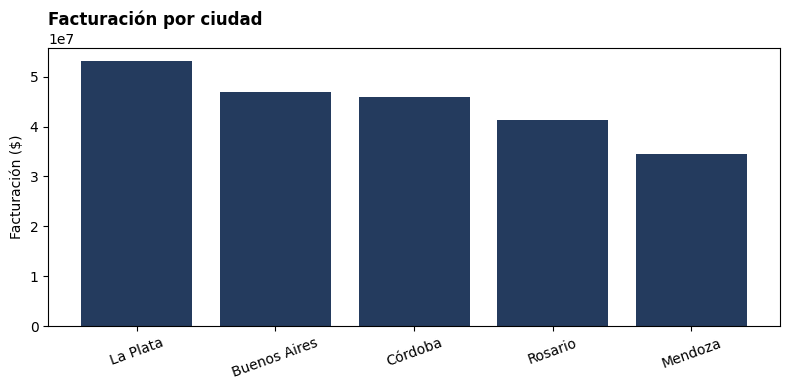

In [26]:
# El resultado de sql() es un DataFrame de pandas → se grafica como cualquier otro
datos = sql("""
    SELECT Ciudad, SUM(Total) AS facturacion
    FROM ventas
    WHERE Ciudad IS NOT NULL      -- sacamos la venta sin ciudad
    GROUP BY Ciudad
    ORDER BY facturacion DESC
""")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(datos["Ciudad"], datos["facturacion"], color="#243b5e")
ax.set_title("Facturación por ciudad", loc="left", fontweight="bold")
ax.set_ylabel("Facturación ($)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

---
## 📜 Qué es un *script* y qué es un *esquema*

Hasta acá escribimos consultas sueltas. Pero en una organización, SQL **no se usa así**: se usa en
**scripts**.

### El script

Un **script** es simplemente **un archivo de texto con varias instrucciones SQL, en orden**, que se
ejecutan una atrás de la otra. La misma idea que un notebook, pero en un `.sql`.

**¿Por qué importa?** Porque una base de datos no se arma a mano clickeando: se arma **corriendo un
script**. Eso tiene tres consecuencias enormes:

| Sin script | Con script |
|---|---|
| Alguien creó las tablas a mano y nadie sabe cómo | La estructura está **escrita y versionada** |
| Rearmar el ambiente de prueba lleva días | Se corre el script y en un minuto está |
| "En mi máquina anda" | Todos parten **exactamente** de lo mismo |

> 🎯 **Es el mismo principio que venimos usando toda la materia:** si está escrito en código, es
> reproducible; si se hizo a mano, se perdió.

> 📌 Para no mezclar, el ejemplo de abajo arma una **base nueva y aparte** (`conexion`), distinta de la de
> la distribuidora (`con`). Tiene su propia tabla `ventas`, más simple.

In [27]:
# Un script típico: crea la estructura, la llena y consulta. Todo junto y en orden.
script = """
-- 1) Definimos la estructura
CREATE TABLE IF NOT EXISTS sucursales (
    id      INTEGER PRIMARY KEY,
    nombre  TEXT    NOT NULL,
    region  TEXT
);

CREATE TABLE IF NOT EXISTS ventas (
    id           INTEGER PRIMARY KEY,
    sucursal_id  INTEGER REFERENCES sucursales(id),   -- clave foránea
    importe      REAL    NOT NULL,
    fecha        TEXT
);

-- 2) Cargamos datos
INSERT INTO sucursales (id, nombre, region) VALUES
    (1, 'Centro',   'AMBA'),
    (2, 'Norte',    'AMBA'),
    (3, 'Córdoba',  'Interior');

INSERT INTO ventas (id, sucursal_id, importe, fecha) VALUES
    (1, 1, 145000, '2026-03-01'),
    (2, 1,  98000, '2026-03-04'),
    (3, 2, 210000, '2026-03-02'),
    (4, 3,  76000, '2026-03-05');
"""

import sqlite3
import pandas as pd

conexion = sqlite3.connect(":memory:")     # una base que vive en memoria, para practicar
conexion.executescript(script)             # ← executescript corre TODO el script de una

print("Base creada. Tablas que existen ahora:")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conexion))

Base creada. Tablas que existen ahora:
         name
0  sucursales
1      ventas


### El esquema

El **esquema** (*schema*) es **el plano de la base**: qué tablas hay, qué columnas tiene cada una, de
qué tipo son y **cómo se relacionan entre sí**.

En el script de arriba, el esquema son los `CREATE TABLE`. Fijate tres cosas que aparecen ahí y que
son las que le dan solidez a una base:

| Elemento | Qué hace | Por qué importa |
|---|---|---|
| **`PRIMARY KEY`** | Identifica cada fila de forma única | Sin esto, terminás con la misma venta cargada dos veces |
| **`REFERENCES`** (clave foránea) | Conecta una tabla con otra | Es **lo que hace posible el `JOIN`** |
| **`NOT NULL`** | Prohíbe que el campo quede vacío | La base **rechaza** el dato malo en vez de guardarlo |

> 💼 **Acá está la diferencia grande con Excel.** En una planilla, cualquiera escribe cualquier cosa
> en cualquier celda. En una base con un buen esquema, **el dato inconsistente ni siquiera entra**:
> la base lo rechaza. Por eso los sistemas serios de una organización corren sobre bases de datos y
> no sobre planillas.

In [28]:
# El esquema se puede consultar: la base sabe describirse a sí misma
print(pd.read_sql("PRAGMA table_info(ventas)", conexion))

print("\nY así se ve el JOIN que las claves hacen posible:")
consulta = """
SELECT  s.nombre           AS sucursal,
        s.region,
        COUNT(v.id)        AS operaciones,
        SUM(v.importe)     AS facturado
FROM        sucursales s
LEFT JOIN   ventas     v ON v.sucursal_id = s.id
GROUP BY    s.nombre, s.region
ORDER BY    facturado DESC
"""
print(pd.read_sql(consulta, conexion))

   cid         name     type  notnull dflt_value  pk
0    0           id  INTEGER        0       None   1
1    1  sucursal_id  INTEGER        0       None   0
2    2      importe     REAL        1       None   0
3    3        fecha     TEXT        0       None   0

Y así se ve el JOIN que las claves hacen posible:
  sucursal    region  operaciones  facturado
0   Centro      AMBA            2 243,000.00
1    Norte      AMBA            1 210,000.00
2  Córdoba  Interior            1  76,000.00


> 🔍 **Mirá el resultado de arriba con atención.** Usamos `LEFT JOIN`, así que aparecen **las tres
> sucursales**, incluso las que tienen pocas ventas. Si hubiéramos usado `INNER JOIN` y alguna
> sucursal no tuviera ninguna venta cargada, **habría desaparecido del informe** — y el gerente de
> esa sucursal se enteraría de que "no existe" en la reunión.

---
# 📝 Ejercicios

Trabajá con la base que ya está cargada. Usá la función `sql("...")`.

**Ejercicio 1.** Traé las 10 ventas de mayor monto, mostrando fecha, producto, vendedor y total.

In [29]:
# Tu respuesta acá

**Ejercicio 2.** ¿Qué productos distintos vendió **Pedro**? ¿Y en qué ciudades vendió?

In [30]:
# Tu respuesta acá

**Ejercicio 3.** ¿Cuántas operaciones y cuánto facturó cada **ciudad**? Ordenado de mayor a menor.
¿Qué pasó con la venta sin ciudad?

In [31]:
# Tu respuesta acá

**Ejercicio 4.** ¿Qué **vendedores** tienen un ticket promedio mayor a \$1.100.000? Escribilo con `HAVING`.
Después probá poner la condición en el `WHERE` (`WHERE Total > 1100000`) y compará los resultados:
¿por qué con `WHERE` aparecen los cinco?

In [32]:
# Tu respuesta acá

**Ejercicio 5.** ¿Cuál es el producto **más rentable** en pesos? (necesitás cruzar con `productos`
y restar el costo).

In [33]:
# Tu respuesta acá

**Ejercicio 6.** Listá los vendedores que **no hicieron ninguna venta**.
Pista: `LEFT JOIN` + `IS NULL`, con la tabla `vendedores` a la izquierda.

In [34]:
# Tu respuesta acá

**Ejercicio 7 (desafío 🥇).** Con un `JOIN` a `vendedores`, calculá por **sucursal** la facturación y **cuántos
vendedores vendieron algo**. Antes de escribirlo, pensá: después del `JOIN` hay una fila por *venta*,
no por *vendedor*. ¿Usás `COUNT(v.Vendedor)` o `COUNT(DISTINCT v.Vendedor)`?

> ⚠️ `Vendedor` está en las dos tablas: si no le ponés el alias adelante (`v.` o `ve.`), SQL no sabe de cuál
> hablás y tira `ambiguous column name`. Pasa con cualquier columna repetida después de un `JOIN`.

In [35]:
# Tu respuesta acá

---
## ✅ Soluciones

Intentalo antes de mirar.

In [36]:
# Solución ejercicio 1
sql("""
    SELECT Fecha, Producto, Vendedor, Total
    FROM ventas
    ORDER BY Total DESC
    LIMIT 10
""")

,Fecha,Producto,Vendedor,Total
0,2024-03-02,Notebook,Lucía,7384500
1,2024-06-11,Notebook,Pedro,7253100
2,2024-06-02,Notebook,María,7250400
3,2024-01-02,Notebook,Lucía,6116600
4,2024-07-12,Notebook,Lucía,6041700
5,2024-01-04,Notebook,Juan,5796000
6,2024-05-03,Notebook,Juan,5734400
7,2024-01-10,Notebook,Juan,5709900
8,2024-04-01,Notebook,María,5579000
9,2024-06-04,Notebook,Juan,5506900


In [37]:
# Solución ejercicio 2: dos consultas con DISTINCT
print(sql("SELECT DISTINCT Producto FROM ventas WHERE Vendedor = 'Pedro' ORDER BY Producto"))
sql("SELECT DISTINCT Ciudad FROM ventas WHERE Vendedor = 'Pedro' ORDER BY Ciudad")

      Producto
0  Auriculares
1    Impresora
2      Monitor
3        Mouse
4     Notebook
5      Teclado


,Ciudad
0,Buenos Aires
1,Córdoba
2,La Plata
3,Mendoza
4,Rosario


In [38]:
# Solución ejercicio 3
sql("""
    SELECT Ciudad, COUNT(*) AS operaciones, SUM(Total) AS facturacion
    FROM ventas
    GROUP BY Ciudad
    ORDER BY facturacion DESC
""")
# La venta sin ciudad no desaparece: forma su propio grupo, con Ciudad = None.

,Ciudad,operaciones,facturacion
0,La Plata,50,53079400
1,Buenos Aires,39,46849600
2,Córdoba,42,45954500
3,Rosario,30,41229600
4,Mendoza,39,34458600
5,None,1,248000


In [39]:
# Solución ejercicio 4
print("Con HAVING (la pregunta que nos hicieron):")
print(sql("""
    SELECT Vendedor, ROUND(AVG(Total)) AS ticket_promedio
    FROM ventas
    GROUP BY Vendedor
    HAVING AVG(Total) > 1100000
"""))

print("\nCon WHERE (otra pregunta):")
sql("""
    SELECT Vendedor, ROUND(AVG(Total)) AS ticket_promedio_de_las_ventas_grandes
    FROM ventas
    WHERE Total > 1100000
    GROUP BY Vendedor
""")
# Con WHERE se descartan las ventas chicas ANTES de promediar. Todos los vendedores tienen alguna venta
# de más de $1,1 millones, así que aparecen los cinco (y con un "promedio" inflado).

Con HAVING (la pregunta que nos hicieron):
  Vendedor  ticket_promedio
0     Juan     1,349,106.00
1    María     1,342,929.00

Con WHERE (otra pregunta):


,Vendedor,ticket_promedio_de_las_ventas_grandes
0,Juan,"2,836,562.00"
1,Lucía,"2,646,593.00"
2,María,"2,914,779.00"
3,Pedro,"2,978,500.00"
4,Sofía,"1,930,043.00"


In [40]:
# Solución ejercicio 5: ganancia = lo vendido menos el costo de lo vendido
sql("""
    SELECT v.Producto, SUM(v.Total - p.Costo * v.Cantidad) AS ganancia
    FROM ventas v
    JOIN productos p ON v.Producto = p.Producto
    GROUP BY v.Producto
    ORDER BY ganancia DESC
    LIMIT 1
""")

,Producto,ganancia
0,Notebook,28865000


In [41]:
# Solución ejercicio 6: LEFT JOIN y quedarse con los que no encontraron pareja
sql("""
    SELECT ve.Vendedor, ve.Sucursal
    FROM vendedores ve
    LEFT JOIN ventas v ON v.Vendedor = ve.Vendedor
    WHERE v.Vendedor IS NULL
""")

,Vendedor,Sucursal
0,Tomás,Sur


In [42]:
# Solución ejercicio 7: COUNT(DISTINCT ...) porque después del JOIN hay una fila por venta
sql("""
    SELECT ve.Sucursal,
           SUM(v.Total)               AS facturacion,
           COUNT(DISTINCT v.Vendedor) AS vendedores_que_vendieron
    FROM ventas v
    JOIN vendedores ve ON v.Vendedor = ve.Vendedor
    GROUP BY ve.Sucursal
    ORDER BY facturacion DESC
""")

,Sucursal,facturacion,vendedores_que_vendieron
0,Centro,113108700,2
1,Norte,71734500,2
2,Sur,36976500,1


---
# 🚀 Para ir más lejos (opcional)

Lo que sigue no hace falta para la clase. Son herramientas que se usan mucho en el trabajo y que te conviene
conocer: funciones que actúan fila por fila, fechas, informes por mes y una subconsulta más compleja.

## 🧮 Funciones: fila por fila o todo en uno

SQL trae funciones, igual que Excel. Hay **dos familias**:

| Familia | Qué hace | Entran → salen | Ejemplos |
|---|---|---|---|
| **De fila** | Transforman cada valor por separado | 201 filas → 201 filas | `ROUND`, `UPPER`, `strftime` |
| **De agregación** | Resumen muchas filas en un solo número | 201 filas → **1** fila | `COUNT`, `SUM`, `AVG`, `MIN`, `MAX` |

En Excel sería la diferencia entre `=REDONDEAR(A2;0)`, que arrastrás fila por fila, y `=SUMA(A2:A201)`,
que te da un solo número.

### Funciones de fila

| Función | Qué hace | Ejemplo | Resultado |
|---|---|---|---|
| `ROUND(x, n)` | Redondea a `n` decimales | `ROUND(3.14159, 2)` | `3.14` |
| `ABS(x)` | Valor absoluto | `ABS(-500)` | `500` |
| `UPPER(t)` / `LOWER(t)` | Pasa a mayúsculas / minúsculas | `UPPER('Rosario')` | `'ROSARIO'` |
| `LENGTH(t)` | Largo del texto | `LENGTH('Mouse')` | `5` |
| `COALESCE(a, b)` | Si `a` es `NULL`, usa `b` | `COALESCE(Ciudad, 'Sin dato')` | `'Sin dato'` |
| `strftime(formato, fecha)` | Saca un pedazo de la fecha | `strftime('%m', '2024-03-15')` | `'03'` |

In [43]:
# Las funciones de fila devuelven un valor POR CADA fila
sql("""
    SELECT Fecha,
           UPPER(Producto)               AS producto,
           COALESCE(Ciudad, 'Sin dato')  AS ciudad,
           Total,
           ROUND(Total / 1000.0, 1)      AS total_miles
    FROM ventas
    ORDER BY Fecha DESC
    LIMIT 5
""")

,Fecha,producto,ciudad,Total,total_miles
0,2024-07-18,IMPRESORA,La Plata,757500,757.50
1,2024-07-17,TECLADO,Rosario,234500,234.50
2,2024-07-16,MONITOR,Mendoza,645600,645.60
3,2024-07-15,MOUSE,Mendoza,156000,156.00
4,2024-07-15,PARLANTE,Sin dato,248000,248.00


### 📅 Fechas

Casi toda pregunta de negocio tiene una fecha adentro: *ventas por mes*, *comparar trimestres*,
*lo que va del año*. En SQLite las fechas se guardan como **texto** con formato `AAAA-MM-DD`, y se
desarman con `strftime`:

| Formato | Qué devuelve | Para `'2024-03-15'` |
|---|---|---|
| `'%Y'` | Año | `'2024'` |
| `'%m'` | Mes | `'03'` |
| `'%Y-%m'` | Año y mes | `'2024-03'` |
| `'%d'` | Día | `'15'` |
| `'%w'` | Día de la semana (0 = domingo) | `'5'` (viernes) |

In [44]:
# Desarmamos la fecha en pedazos
sql("""
    SELECT Fecha,
           strftime('%Y', Fecha)     AS anio,
           strftime('%m', Fecha)     AS mes,
           strftime('%Y-%m', Fecha)  AS periodo,
           strftime('%w', Fecha)     AS dia_semana
    FROM ventas
    LIMIT 5
""")

,Fecha,anio,mes,periodo,dia_semana
0,2024-01-01,2024,01,2024-01,1
1,2024-01-02,2024,01,2024-01,2
2,2024-01-03,2024,01,2024-01,3
3,2024-01-04,2024,01,2024-01,4
4,2024-01-05,2024,01,2024-01,5


In [45]:
# Filtrar un período: las ventas de marzo
sql("""
    SELECT Fecha, Producto, Total
    FROM ventas
    WHERE Fecha BETWEEN '2024-03-01' AND '2024-03-31'
    LIMIT 5
""")

,Fecha,Producto,Total
0,2024-03-01,Monitor,1154500
1,2024-03-02,Notebook,7384500
2,2024-03-03,Teclado,70000
3,2024-03-04,Impresora,1911200
4,2024-03-05,Auriculares,97200


> ⚠️ **Esto anda porque la fecha está en formato `AAAA-MM-DD`:** escrita así, el orden alfabético
> coincide con el del calendario. Si la base tuviera `15/03/2024`, el `BETWEEN` compararía textos y
> daría cualquier cosa. Es de lo primero que hay que mirar cuando te pasan una base:
> **en qué formato vienen las fechas**.

### Agrupar por fecha

Con `strftime` en el `GROUP BY` sale el clásico **informe mensual**:

In [46]:
sql("""
    SELECT strftime('%Y-%m', Fecha)  AS mes,
           COUNT(*)                  AS operaciones,
           SUM(Total)                AS facturacion
    FROM ventas
    GROUP BY strftime('%Y-%m', Fecha)
    ORDER BY mes
""")

,mes,operaciones,facturacion
0,2024-01,31,42124800
1,2024-02,29,28604500
2,2024-03,31,40051600
3,2024-04,30,22044900
4,2024-05,31,32623100
5,2024-06,30,40306200
6,2024-07,19,16064600


> ⚠️ **Mirá julio:** factura menos que todos los demás meses. ¿Vendimos peor? No: los datos llegan
> hasta el 18 de julio. **Un mes incompleto no se compara con uno completo.** Antes de sacar
> conclusiones de un informe por fecha, fijate desde cuándo y hasta cuándo hay datos
> (`MIN(Fecha)`, `MAX(Fecha)`).

### Contar distintos dentro de cada grupo

In [47]:
# ¿Cuántas operaciones hizo cada vendedor, y cuántos productos y ciudades DISTINTOS?
sql("""
    SELECT Vendedor,
           COUNT(*)                  AS operaciones,
           COUNT(DISTINCT Producto)  AS productos_distintos,
           COUNT(DISTINCT Ciudad)    AS ciudades_distintas
    FROM ventas
    GROUP BY Vendedor
    ORDER BY operaciones DESC
""")

,Vendedor,operaciones,productos_distintos,ciudades_distintas
0,Juan,49,6,5
1,Lucía,46,6,5
2,Pedro,41,6,5
3,María,35,6,5
4,Sofía,30,7,5


### 🪆 Una subconsulta más: agrupar dos veces

**Otro ejemplo.** *¿Cuánto factura, en promedio, un vendedor de cada sucursal?*

Acá hay que agrupar **dos veces**: primero por vendedor (para tener lo que facturó cada uno) y después
por sucursal (para promediar esos totales). Una sola agrupación no alcanza.

1. **Adentro:** la facturación de cada vendedor, con su sucursal.
2. **Afuera:** el promedio de esos totales, por sucursal.

Leámoslo por partes. Primero, lo de adentro solo:

In [48]:
# Paso 1, solo: lo que calcula la subconsulta (una fila por vendedor)
sql("""
    SELECT ve.Sucursal, v.Vendedor, SUM(v.Total) AS facturacion
    FROM ventas v
    JOIN vendedores ve ON v.Vendedor = ve.Vendedor
    GROUP BY ve.Sucursal, v.Vendedor
""")

,Sucursal,Vendedor,facturacion
0,Centro,Juan,66106200
1,Centro,María,47002500
2,Norte,Lucía,50074600
3,Norte,Sofía,21659900
4,Sur,Pedro,36976500


Y ahora la consulta completa: la de afuera usa ese resultado **como si fuera una tabla más** de la base.

In [49]:
# Paso 2: la consulta completa (la subconsulta hace de tabla)
sql("""
    SELECT Sucursal,
           ROUND(AVG(facturacion)) AS facturacion_promedio_por_vendedor
    FROM (
        SELECT ve.Sucursal, v.Vendedor, SUM(v.Total) AS facturacion
        FROM ventas v
        JOIN vendedores ve ON v.Vendedor = ve.Vendedor
        GROUP BY ve.Sucursal, v.Vendedor
    )
    GROUP BY Sucursal
    ORDER BY facturacion_promedio_por_vendedor DESC
""")

,Sucursal,facturacion_promedio_por_vendedor
0,Centro,"56,554,350.00"
1,Sur,"36,976,500.00"
2,Norte,"35,867,250.00"


> 💡 En el Ejemplo 1 la subconsulta devolvía **un número**; en el Ejemplo 2 devuelve **una tabla entera**.
> Son los dos usos más comunes. Cuando veas un `SELECT` dentro de otro, no te asustes: buscá el
> paréntesis, leé eso primero, y después el resto.

### Más ejercicios

**Ejercicio 8.** ¿Qué **día de la semana** se factura más? Pista: `strftime('%w', Fecha)`, donde
0 es domingo.

In [50]:
# Tu respuesta acá

**Ejercicio 9.** Resolvé el Ejercicio 3 **otra vez**, pero con pandas (`groupby` + `agg`).
¿Te da la misma cantidad de ciudades que con SQL? Si no, ¿por qué? Pista: fijate qué hace cada uno
con la venta sin ciudad.

In [51]:
# Tu respuesta acá

**Ejercicio 10 (integrador).** El gerente comercial te pide un informe para la reunión de resultados.
Para cada **mes** y cada **categoría** de producto, mostrá:

- la cantidad de operaciones,
- cuántos **vendedores distintos** vendieron esa categoría ese mes,
- la facturación y la ganancia (venta menos costo),
- el margen en %, redondeado a 1 decimal.

Condiciones:

- solo las ventas con **ciudad cargada**,
- solo de **enero a junio** (julio está incompleto),
- solo las combinaciones que facturaron **más de \$3.000.000**,
- ordenado por mes y, dentro de cada mes, por ganancia de mayor a menor.

No hace falta ninguna subconsulta. 

In [52]:
# Tu respuesta acá

In [53]:
con.close()   # buena práctica: cerrar la conexión cuando terminás
print("Conexión cerrada ✅")

Conexión cerrada ✅


---
## 🏢 Para leer en casa: cómo se organiza una empresa de software (y por qué te importa)

Cuando trabajes con datos en una organización, **la base de datos no te la vas a encontrar sola**:
es una pieza de un sistema más grande, hecho y mantenido por un equipo. Estas palabras se van a usar
delante tuyo el primer día, así que conviene tenerlas claras.

### Las dos mitades de cualquier sistema

| | **Front-end** | **Back-end** |
|---|---|---|
| **Qué es** | Lo que el usuario ve y toca | La maquinaria que no se ve |
| **Dónde corre** | En la pantalla del usuario | En un servidor |
| **De qué se ocupa** | Botones, formularios, gráficos | Reglas de negocio, cálculos, **la base de datos** |
| **Ejemplo** | La pantalla del homebanking | Lo que verifica que tengas saldo |

**¿Dónde entra SQL?** En el back-end, siempre. Cuando alguien aprieta "Ver mis movimientos", el
front-end le pide los datos al back-end, y el back-end **hace exactamente el tipo de consulta que
venimos escribiendo en esta clase**. La consulta que escribís vos es la misma que corre adentro de
esa aplicación.

### El deploy

**Hacer un *deploy*** (o "deployar", como se dice) es **poner en producción**: pasar el código que
estaba en la computadora del programador al servidor donde lo usa la gente de verdad.

Para entenderlo hay que saber que existen **ambientes separados**:

| Ambiente | Para qué sirve | Si rompés algo acá… |
|---|---|---|
| **Desarrollo** | Donde el programador prueba | No pasa nada |
| **Testing / QA** | Donde se verifica que ande | Lo encuentra el equipo de prueba |
| **Producción** | El sistema real, con datos reales | **Lo sufren los clientes** |

> 🚨 **La regla de oro, y la razón por la que esto entra en una clase de datos:** nunca se prueba una
> consulta en producción. Un `SELECT` mal escrito puede trabar la base; un `UPDATE` o un `DELETE` sin
> `WHERE` **borra o pisa datos reales**. Si alguna vez te dan acceso a la base de una empresa,
> preguntá **siempre** en qué ambiente estás parado antes de escribir nada.

### Otras palabras que vas a escuchar

| Palabra | Qué significa |
|---|---|
| **API** | La puerta por la que dos sistemas se hablan entre sí |
| **Repositorio** (*repo*) | Donde vive el código versionado — como este repo de la materia en GitHub |
| **Query** | Una consulta a la base. Es lo que venimos escribiendo |
| **ETL** | *Extract, Transform, Load*: traer datos, limpiarlos y cargarlos. **Es literalmente lo que hacemos en esta materia** |
| **Data warehouse** | Una base pensada para analizar, separada de la que usa el sistema día a día |
| **Bug** | Un error en el código |
| **Rollback** | Volver atrás un cambio que salió mal |

> 💡 **Por qué te lo contamos:** el perfil que buscan las organizaciones no es el que solo sabe SQL,
> sino el que **entiende dónde está parado**: de dónde salen los datos, quién los genera, qué pasa si
> se rompen. Con este vocabulario podés sentarte en esa reunión y entender de qué se está hablando.

---
## 🧭 Para llevarse

```sql
SELECT   columnas, FUNCION(columna) AS alias
FROM     tabla  alias
JOIN     otra_tabla alias2  ON  alias.clave = alias2.clave
WHERE    condición sobre filas
GROUP BY columnas_no_agregadas
HAVING   condición sobre grupos
ORDER BY columna DESC
LIMIT    n
```

**Ese bloque es el 90% del SQL que vas a escribir en tu vida laboral.** El orden de las cláusulas
no es negociable: si ponés el `WHERE` después del `GROUP BY`, no anda.

**Los cinco errores que más se cometen:**
1. Usar `==` en vez de `=`.
2. Olvidarse el `ON` en un `JOIN` (y quedarse con miles de filas fantasma).
3. Poner en `WHERE` una condición sobre un total, que va en `HAVING`.
4. Buscar vacíos con `= NULL` en vez de `IS NULL`.
5. Contar con `COUNT(*)` después de un `LEFT JOIN`, o con `COUNT` donde iba `COUNT(DISTINCT ...)`.

**Y un hábito:** después de cada `JOIN`, contá las filas.